In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

ModuleNotFoundError: No module named 'pandas'

In [3]:
%pip install pandas numpy matplotlib seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.6 MB 4.5 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.6 MB 4.8 MB/s eta 0:00:02
   ---------- ----------------------------- 2.6/9.6 MB 4.0 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.6 MB 3.9 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.6 MB 3.7 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.6 MB 3.6 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.6 MB 3.7 MB/s eta 0:00:02
   -------------------------- ------------- 6.3/9.6 MB 3.7 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.6 MB 3.7 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.6 


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:
import pandas as pd

df = pd.read_csv("data/Titanic-Dataset.csv")

df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df.shape

(891, 12)

In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


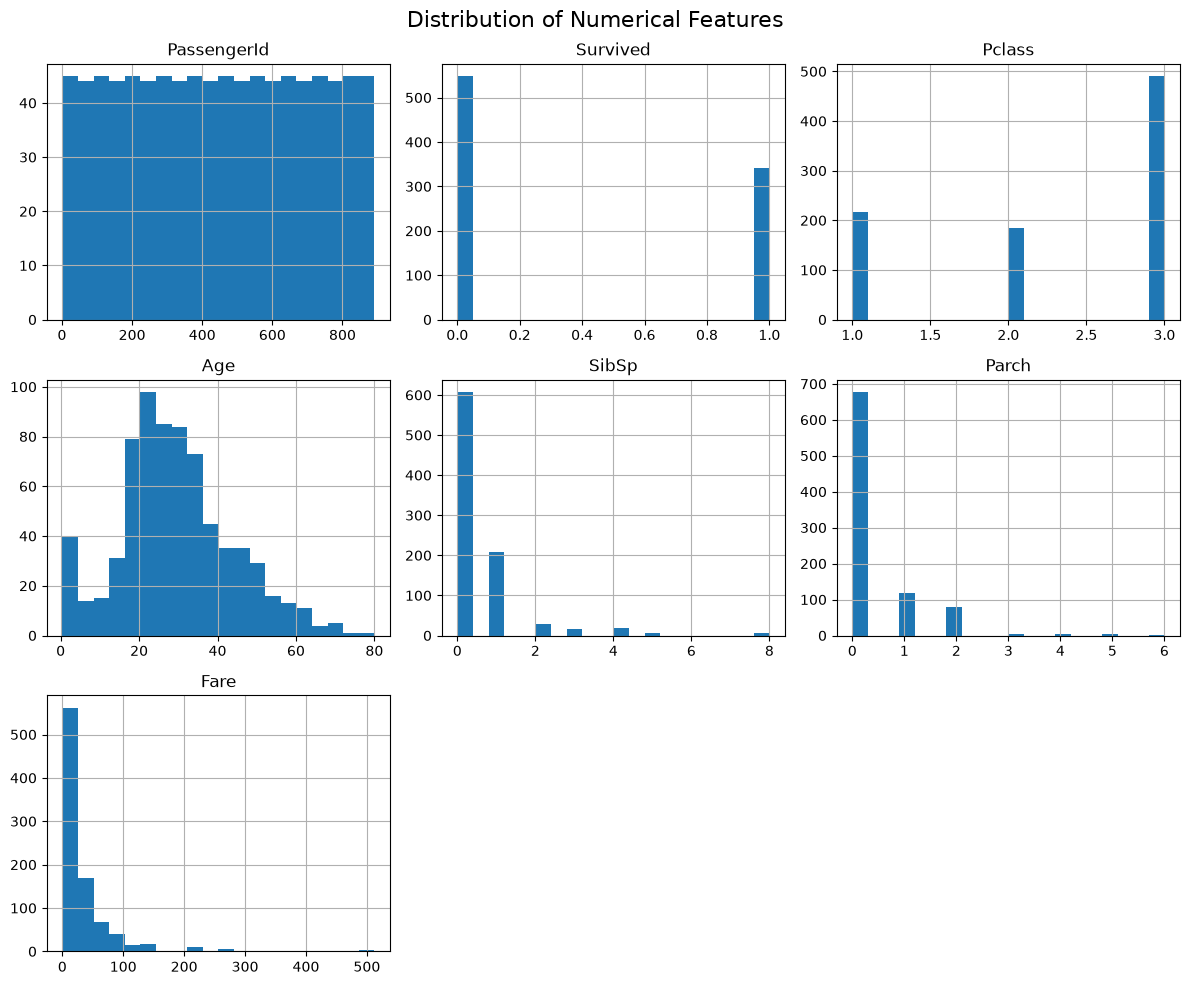

In [10]:
# Histograms for numerical features

df.hist(figsize=(12, 10), bins=20)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

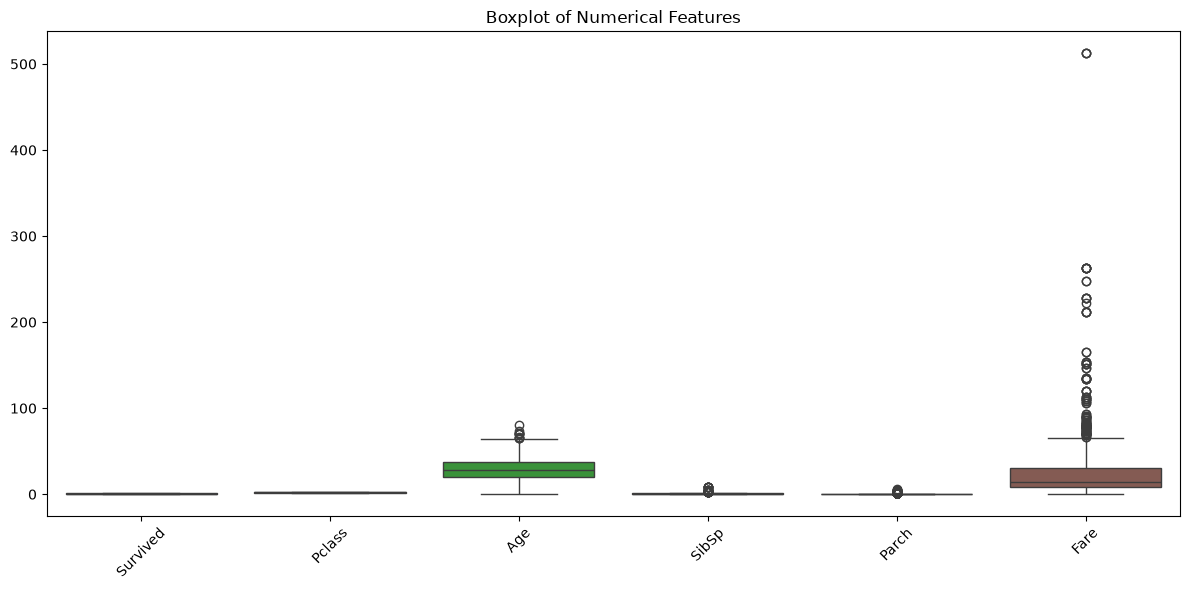

In [11]:
# Boxplots for numerical features

numeric_columns = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numeric_columns])

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

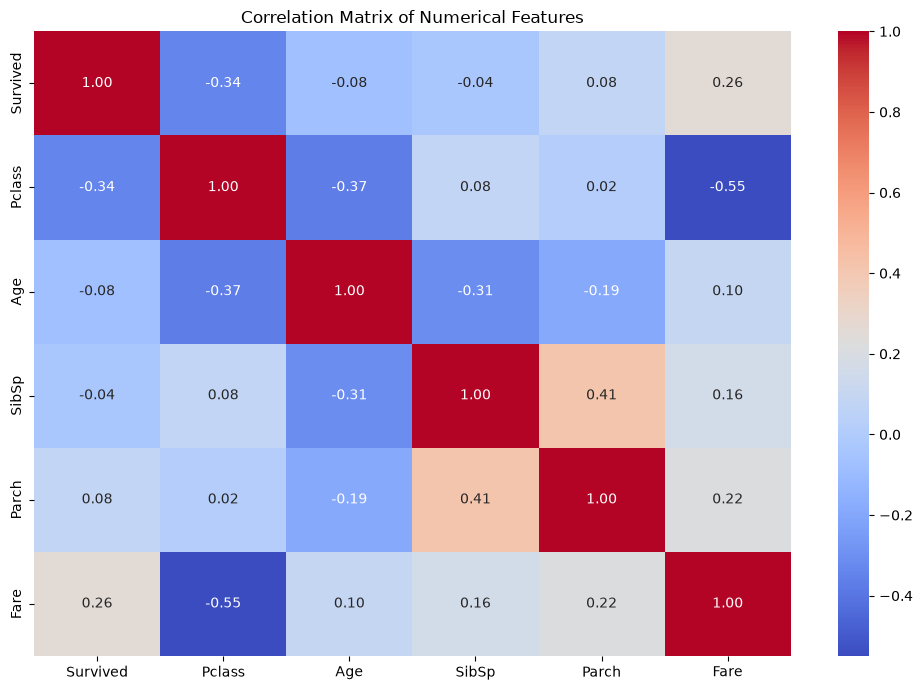

In [12]:
# Correlation matrix

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

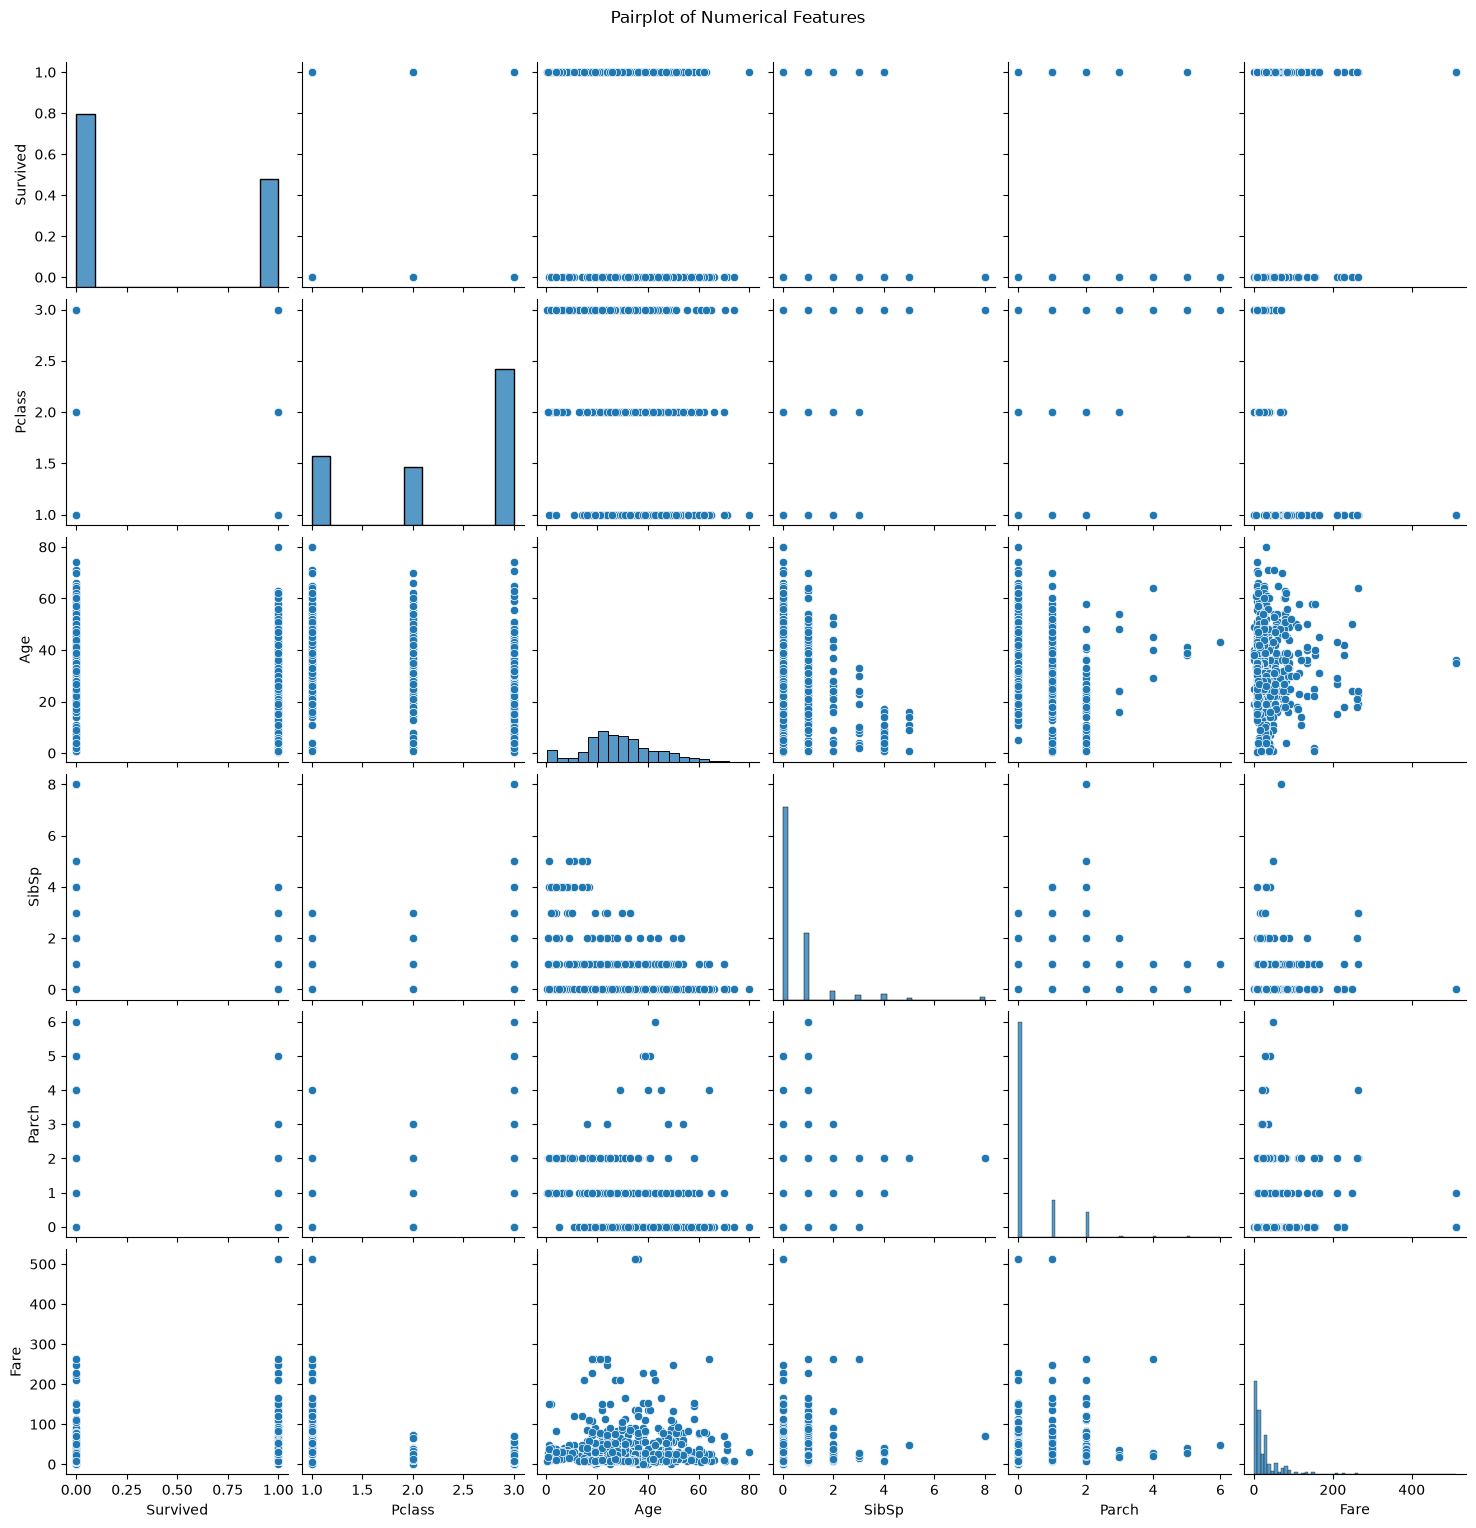

In [13]:
# Pairplot for feature relationships

sns.pairplot(
    df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']],
    diag_kind='hist'
)

plt.suptitle("Pairplot of Numerical Features", y=1.02)
plt.show()

In [14]:
# Survival rate by gender

survival_by_gender = df.groupby('Sex')['Survived'].mean()

print("Survival Rate by Gender:")
print(survival_by_gender)

Survival Rate by Gender:
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


In [15]:
# Survival rate by passenger class

survival_by_class = df.groupby('Pclass')['Survived'].mean()

print("Survival Rate by Passenger Class:")
print(survival_by_class)



Survival Rate by Passenger Class:
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


In [16]:
# Checking potential outliers using IQR

Q1 = df[['Age', 'Fare']].quantile(0.25)
Q3 = df[['Age', 'Fare']].quantile(0.75)

IQR = Q3 - Q1

outliers = ((df[['Age', 'Fare']] < (Q1 - 1.5 * IQR)) |
            (df[['Age', 'Fare']] > (Q3 + 1.5 * IQR))).sum()

print("Potential outliers:")
print(outliers)



Potential outliers:
Age      11
Fare    116
dtype: int64
